In [142]:
from sklearn.svm import SVR
from sklearn.model_selection import train_test_split, RandomizedSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import root_mean_squared_error
from matplotlib import pyplot as plt
import pandas as pd
import numpy as np

df = pd.read_csv("concrete_data.csv")
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1030 entries, 0 to 1029
Data columns (total 9 columns):
 #   Column                         Non-Null Count  Dtype  
---  ------                         --------------  -----  
 0   cement                         1030 non-null   float64
 1   blast_furnace_slag             1030 non-null   float64
 2   fly_ash                        1030 non-null   float64
 3   water                          1030 non-null   float64
 4   superplasticizer               1030 non-null   float64
 5   coarse_aggregate               1030 non-null   float64
 6   fine_aggregate                 1030 non-null   float64
 7   age                            1030 non-null   int64  
 8   concrete_compressive_strength  1030 non-null   float64
dtypes: float64(8), int64(1)
memory usage: 72.6 KB


In [143]:
X = df.drop(columns=['concrete_compressive_strength'])
y = df['concrete_compressive_strength']

In [144]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)

In [145]:
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [146]:
param_dist = {
    'kernel': ['rbf'],
    'C': [10, 100, 500, 1000],
    'gamma': ['scale', 'auto', 0.1, 1],
    'epsilon': [0.1, 0.5, 1.0, 2.0]
}

random_search = RandomizedSearchCV(
    estimator=SVR(),
    param_distributions=param_dist,
    n_iter=10,
    cv=5,
    scoring='neg_root_mean_squared_error',
    verbose=2
)
random_search.fit(X_train_scaled, y_train)
print(f"Migliori parametri: {random_search.best_params_}")
print(f"Miglior accuracy in CV: {random_search.best_score_:.4f}")

Fitting 5 folds for each of 10 candidates, totalling 50 fits
[CV] END ...........C=1000, epsilon=0.1, gamma=1, kernel=rbf; total time=   0.0s
[CV] END ...........C=1000, epsilon=0.1, gamma=1, kernel=rbf; total time=   0.0s
[CV] END ...........C=1000, epsilon=0.1, gamma=1, kernel=rbf; total time=   0.0s
[CV] END ...........C=1000, epsilon=0.1, gamma=1, kernel=rbf; total time=   0.0s
[CV] END ...........C=1000, epsilon=0.1, gamma=1, kernel=rbf; total time=   0.0s
[CV] END ........C=100, epsilon=0.5, gamma=scale, kernel=rbf; total time=   0.0s
[CV] END ........C=100, epsilon=0.5, gamma=scale, kernel=rbf; total time=   0.0s
[CV] END ........C=100, epsilon=0.5, gamma=scale, kernel=rbf; total time=   0.0s
[CV] END ........C=100, epsilon=0.5, gamma=scale, kernel=rbf; total time=   0.0s
[CV] END ........C=100, epsilon=0.5, gamma=scale, kernel=rbf; total time=   0.0s
[CV] END ...........C=10, epsilon=0.1, gamma=0.1, kernel=rbf; total time=   0.0s
[CV] END ...........C=10, epsilon=0.1, gamma=0.1

In [147]:
svr = SVR(C=100, kernel="rbf", gamma=0.1, epsilon=2)
svr.fit(X_train_scaled, y_train)
y_pred = svr.predict(X_test_scaled)
rmse = root_mean_squared_error(y_test, y_pred)
print(rmse)

6.2462282832191915


In [148]:
from sklearn.metrics import r2_score

r2 = r2_score(y_test, y_pred)
print(r2)

0.8558053273240774


c:\Users\rdarc\AppData\Local\Programs\Python\Python311\Lib\site-packages\sklearn\utils\validation.py:2827: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(


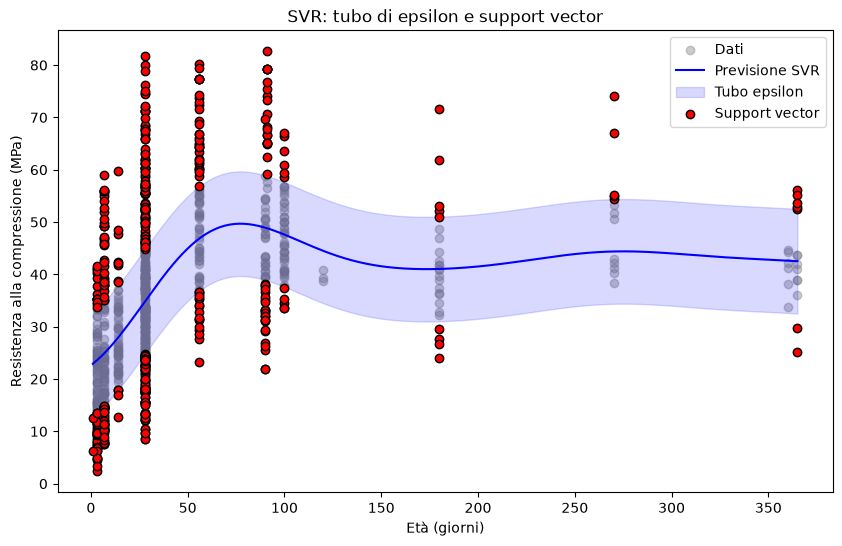

In [ ]:
X_single = df[['age']]

scaler_single = StandardScaler()
X_single_scaled = scaler_single.fit_transform(X_single)

svr_dummy = SVR(epsilon=15, kernel='rbf')
svr_dummy.fit(X_single_scaled, y)

X_smooth = np.linspace(df['age'].min(), df['age'].max(), 300).reshape(-1, 1)
X_smooth_scaled = scaler_single.transform(X_smooth)
y_smooth = svr_dummy.predict(X_smooth_scaled)
X_smooth_flat = X_smooth.ravel()

plt.figure(figsize=(10, 6))
plt.scatter(X_single, y, alpha=0.4, color='gray', label='Dati')
plt.plot(X_smooth_flat, y_smooth, color='blue', label='Previsione SVR')
plt.fill_between(X_smooth_flat, y_smooth - svr_dummy.epsilon, y_smooth + svr_dummy.epsilon,
                  color='blue', alpha=0.15, label='Tubo epsilon')
plt.scatter(df['age'].values[svr_dummy.support_], y.values[svr_dummy.support_],
            color='red', edgecolor='black', label='Support vector', zorder=5)

plt.xlabel('Età (giorni)')
plt.ylabel('Resistenza alla compressione (MPa)')
plt.title('SVR: tubo di epsilon e support vector')
plt.legend()
plt.show()